In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import pandas as pd
from tabulate import tabulate
plt.style.use('bmh')

## Climate Related Disasters in Argentina
#### Climate 423 Course Project
#### Maydine Bellot

### Introduction

According to the World Meteorological Organization, the number of weather-related disasters has been increasing over the last 50 years. For this project, I aim to analyze the overall trends of 6 disaster types in Argentina (landslides, extreme temperatures, wildfires, storms, droughts, and flooding), observe which disasters occur more frequently, and assess the correlation of storms and flood events to each other. I want to use this information to infer which disasters have the largest impact in Argentina by population, as well as notice the overall trends for these disasters occurring.
I will start by creating a time series plot of the datasets I found, the number of people affected by each disaster type from 1980-2024, as well as the number of occurrences of each disaster type from 1980-2024. This will help me to visualize the data before starting my analysis. Then, I will evaluate the trends of these disaster occurrences, assess the correlation of storm and flood occurrences, and finally use event detection metrics to compare between storm and flood occurrences.

### Part 1: Describing and Visualizing Dataset

I will start by reading in the dataset. The dataset I chose is the Climate-related Disasters Frequency dataset from the macroeconomic climate indicators dashboard. This dataset records the frequency of climate related natural disasters by countries, as well as the number of people affected by these disasters. The disaster categories include landslides, extreme temperatures, wildfires, storms, droughts, and flooding. I chose to look at Argentina for this because it has a large range of biomes which experience a variety of disasters. I chose to specifically look at data from the entire dataset, 1980-2024 to better assess the overall trends and relationships.

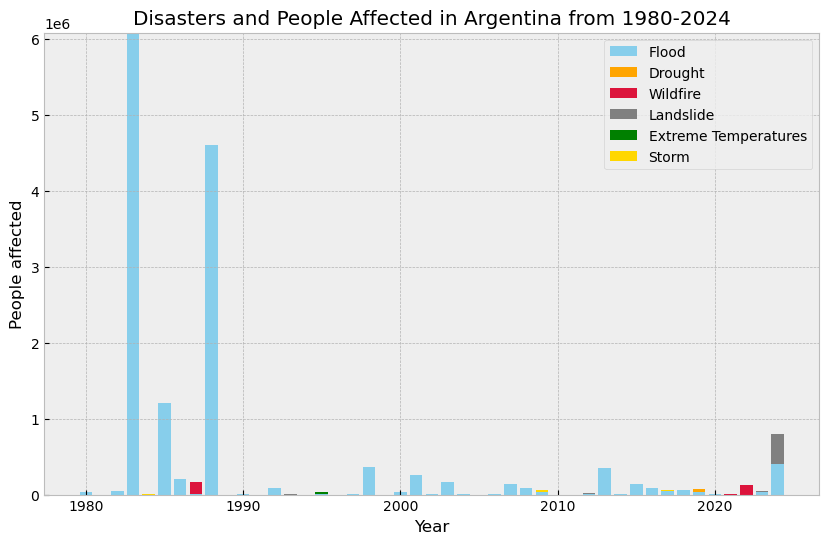

In [2]:
#reading in data using genfromtxt
df = np.genfromtxt('Argentina_ Climate_related_disasters_frequency_1980_2024.csv', delimiter=',',skip_header=1,filling_values=0, 
                   names=('year', 'drought', 'temp','flood', 'landslide','storm','total','wildfire',
                          'drought_pop', 'temp_pop','flood_pop', 'storm_pop','landslide_pop','total_pop', 'wildfire_pop'), dtype=float)

# assigning variables
year = df['year']
drought = df['drought']
temp = df['temp']
flood = df['flood']
landslide = df['landslide']
storm = df['storm']
wildfire = df['wildfire']
total = df['total']

drought_pop = df['drought_pop']
temp_pop = df['temp_pop']
flood_pop = df['flood_pop']
landslide_pop = df['landslide_pop']
wildfire_pop = df['wildfire_pop']
storm_pop = df['storm_pop']
total_pop = df['total_pop']

#plotting the popualtion affected by these events by year with a barplot
plt.figure(figsize=(10,6))
plt.bar(year, flood_pop, color='skyblue', label='Flood')
plt.bar(year, drought_pop, bottom=flood_pop, color='orange', label = 'Drought')
plt.bar(year, wildfire_pop, bottom=flood_pop+drought_pop, color='crimson', label='Wildfire')
plt.bar(year, landslide_pop, bottom=flood_pop+drought_pop+wildfire_pop,color='grey', label='Landslide')
plt.bar(year, temp_pop, color = 'green', bottom=flood_pop+drought_pop+wildfire_pop+landslide_pop,label='Extreme Temperatures')
plt.bar(year, storm_pop, color='gold',  bottom=flood_pop+drought_pop+wildfire_pop+landslide_pop+temp_pop,label='Storm')
plt.title('Disasters and People Affected in Argentina from 1980-2024')
plt.xlabel('Year')
plt.ylabel('People affected')
plt.legend()


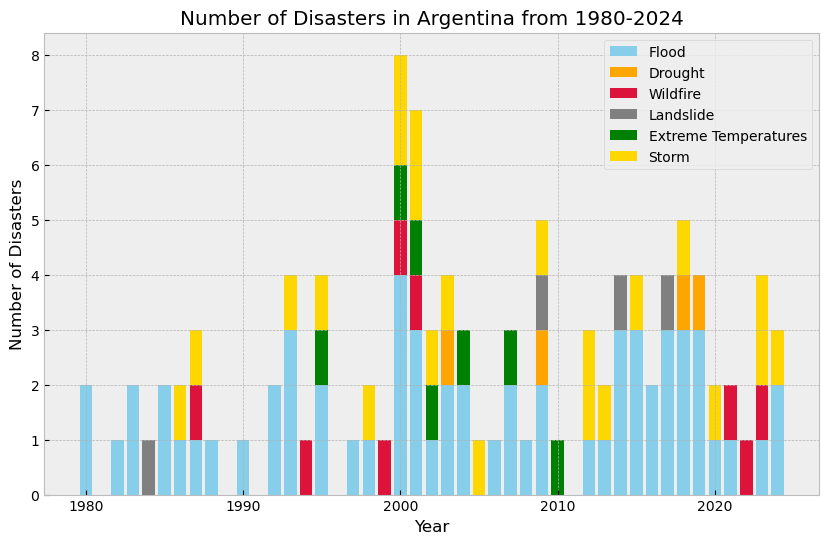

In [3]:
#plotting the number of events per year using a barplot
plt.figure(figsize=(10,6))
plt.bar(year, flood,color='skyblue', label='Flood')
plt.bar(year, drought, bottom=flood,color='orange', label = 'Drought')
plt.bar(year, wildfire, bottom=flood+drought, color='crimson', label='Wildfire')
plt.bar(year, landslide, bottom=flood+drought+wildfire,color='grey', label='Landslide')
plt.bar(year, temp, bottom=flood+drought+wildfire+landslide, color = 'green', label='Extreme Temperatures')
plt.bar(year, storm,bottom=flood+drought+wildfire+landslide+temp, color='gold', label='Storm')
plt.title('Number of Disasters in Argentina from 1980-2024')
plt.xlabel('Year')
plt.ylabel('Number of Disasters')
plt.legend()

After reading in the data, I created 2 plots to visualize the data before my analysis. In the first plot, we can see the number of people affected by each of the climate related disasters in Argentina. From this plot it is clear that floods affect the largest amount of population. In the second plot, we can see the number of occurrences of these disasters for each year. Here, we can see that floods are the most frequently occurring natural disasters. For this project, I will be focusing on the number of occurrences of disasters, including trends and their occurrences in relation to each other.

### Part 2: Linear Fitting and Evaluating Trends

To start I will perform linear regressions for the number of occurrences of the disasters to determine the overall trends of these disasters over this time period.

Flood slope is 0.0179 occurances/year
Drought slope is 0.0054 occurances/year
Wildfire slope is 0.0041 occurances/year
Landslide slope is 0.0021 occurances/year
Extreme Temperatures slope is 0.0007 occurances/year
Storm slope is 0.0126 occurances/year
Total slope is 0.0428 occurances/year


Text(0.5, 0, 'Year')

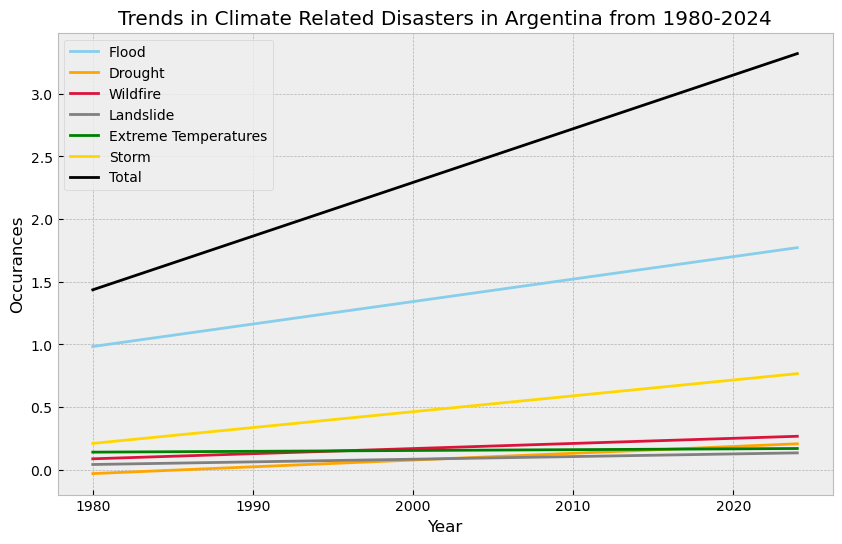

In [4]:
#performing linear fit for the numer of disasters each year
def linear_fit(value, name, color, ax):
    '''
    This function takes the array of data, name of the data, and color
    used to represent the data in the plot. Then it performs a linear
    fit of the data, and plots this on the chart with the assigned color
    and giving it the label of the name. It also prints the slope of each
    dataset.
    '''
    #getting coefficients using np.polyfit
    coeff = np.polyfit(year, value, 1)
    m, c = coeff
    y = m*year + c
    #plotting linear fit
    ax.plot(year, y, label=name, color=color)
    #plt.scatter(year, value, label=f"{name} data", color=color)
    #prining out information about slope
    print(f"{name} slope is {m.round(4)} occurances/year")

#creating figure for our plots
plt.figure(figsize=(10,6))

#calling linear fit function I made to peform linear fit
linear_fit(flood, 'Flood', 'skyblue', plt)
linear_fit(drought, 'Drought', 'orange', plt)
linear_fit(wildfire, 'Wildfire', 'crimson', plt)
linear_fit(landslide, 'Landslide', 'grey', plt)
linear_fit(temp, 'Extreme Temperatures', 'green', plt)
linear_fit(storm, 'Storm', 'gold', plt)
linear_fit(total, 'Total', 'black', plt)

#formatting
plt.legend()
plt.title('Trends in Climate Related Disasters in Argentina from 1980-2024')
plt.ylabel('Occurances')
plt.xlabel('Year')
    

During this period, the occurrences of climate related disasters is increasing for all 6 types of disasters. It also shows a steep increase in the total number of disasters, with a slope of 0.0428 occurrences per year. This is very compelling evidence that the occurrences of natural disasters are increasing. After creating this plot, I notice that storms and flooding both have a high number of occurrences compared to the rest of the disasters, and their number of occurrences per year appear to be increasing at a similar rate. Because of this, I will choose to focus on evaluating the correlation of storm and flood occurrences for the remainder of this project.

### Part 3: Assessment of the correlation
To assess correlation, I will start by creating a 2d histogram of the storm and flood occurrences by year. Using a 2d histogram here is easier to visualize the correlation than a scatterplot because the shading helps to see where there is a higher frequency of occurances. I will also find a linear fit to a scatterplot of the values to assess the trendline. Finally, I will calculate the correlation coefficient as well as the p-value.

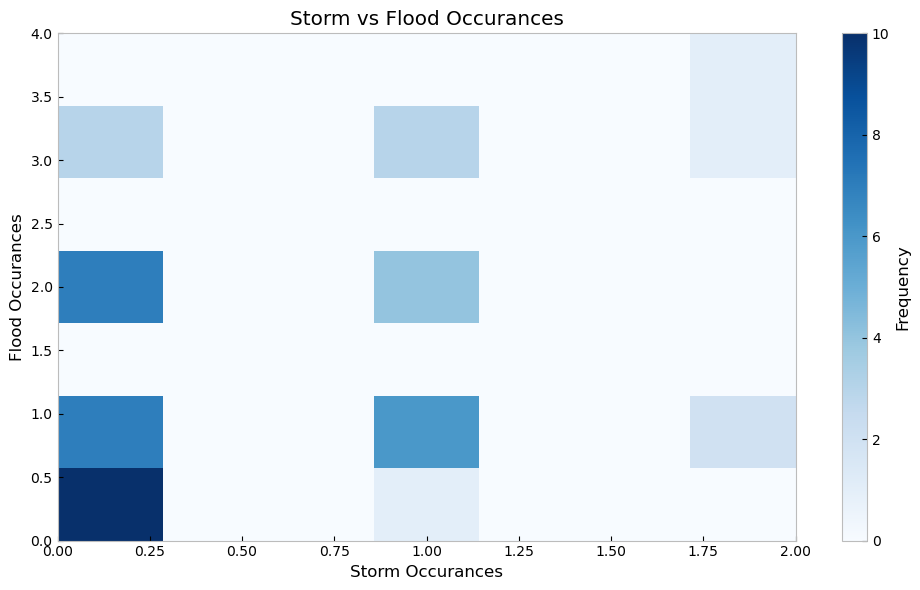

In [5]:
# make a 2d histogram to visually evalute correlation between storm and flood occurances
N = np.sqrt(storm.size).round()
plt.figure(figsize=(10,6))
plt.hist2d(storm, flood, bins = N.astype(int), cmap='Blues')
plt.title('Storm vs Flood Occurances')
plt.xlabel('Storm Occurances')
plt.ylabel('Flood Occurances')
plt.colorbar(label='Frequency')
plt.grid()
plt.tight_layout()


Trendline slope is 0.555427251732102


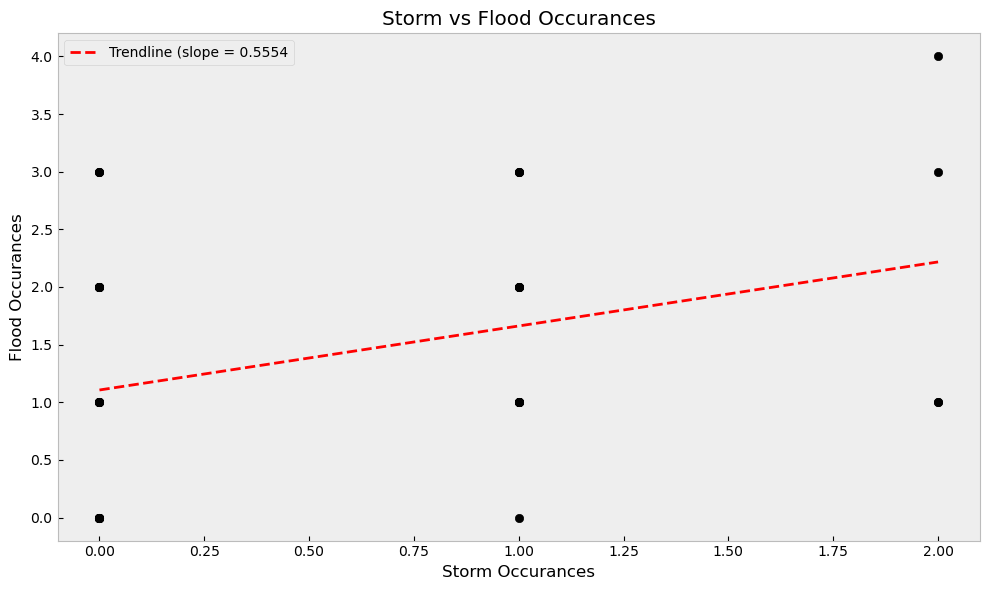

In [6]:
#scatterplot with fit line

#calculating fit line
coeffs = np.polyfit(storm, flood, 1)
m, c = coeffs
x = np.arange(0,2.5, 0.5)

#plotting scatterplot and fit line on same plot
plt.figure(figsize=(10,6))
plt.scatter(storm, flood, color='black')
plt.plot(x, x*m + c, color='red', ls='--', label='Trendline (slope = 0.5554')
plt.title('Storm vs Flood Occurances')
plt.xlabel('Storm Occurances')
plt.ylabel('Flood Occurances')
plt.grid()
plt.legend()
plt.tight_layout()

print(f"Trendline slope is {m}")

In [7]:
# Calculate pearson linear correlation coefficient and determine probability on this score
pearson_coeff, p_value = stats.pearsonr(storm, flood) #calculating pearson coefficient and probability for storm and flood occurances
print(f"Pearson Correlation Coefficient is {pearson_coeff}")
print(f"Probability for this score is {p_value}")

Pearson Correlation Coefficient is 0.3360305480135466
Probability for this score is 0.02402068208584501


The histogram shows that there is a high frequency of occurrences where there are both 0 storms and 0 floods, showing the data is correlated for these lower values. However, there visually appears to be less of a correlation with the number of flood and storm events when they are 1 event of greater. The trendline presented on the scatterplot has a slope of 0.555. This gives more insight, telling us that the number of storms and floods are positively correlated. The correlation coefficient is 0.336, which is below the threshold of a strong correlation between the two variables. The p value for the correlation coefficient is 0.024, showing that we can reject the null hypothesis, and there is likely a relationship between storm and flood occurrences. This is critical information because although the correlation coefficient is below the threshold of a strong correlation, this still points towards the disasters being somewhat correlated and not completely random.


### Part 4: Event Detection Metrics to Compare Between Datasets
In this part of the project, I will use event detection metrics to investigate the relationship between storm and flood occurrences in Argentina. I will assign event status to when occurrences of storms and floods are 1 or greater. 

Floods   0   1
Storms        
0       10  17
1        1  17


Text(0, 0.5, 'Count')

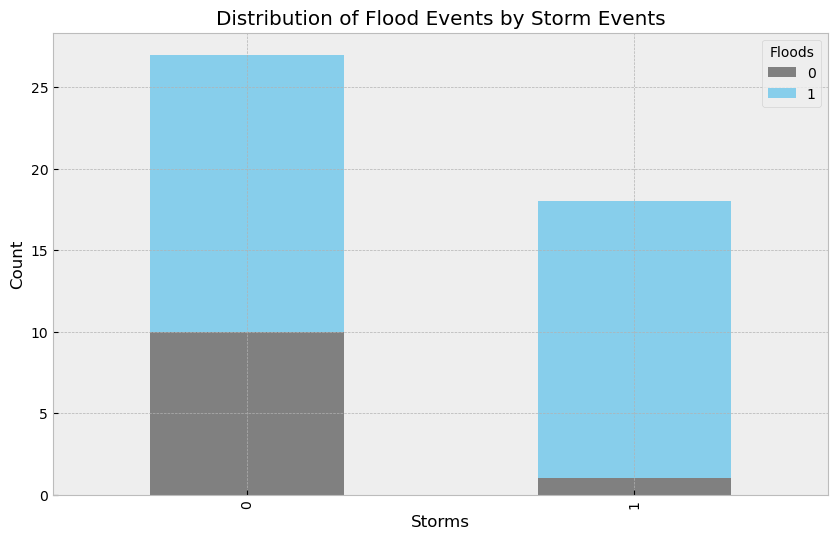

In [8]:
#Assigning event status for when  occurances are 1 or greater for event detection, trying to see if disasters could be related
status_s = np.where(storm > 0, 1, 0) #1 is for an event and 0 is for no event
status_f = np.where(flood > 0, 1, 0)

#calculting the contingency table using pd.crosstab and printing
contingency_table = pd.crosstab(status_s.astype(str), status_f.astype(str), rownames=['Storms'], colnames=['Floods'])
print(contingency_table)

#creating a hisogram to better visualize the results form the contingency table
contingency_table.plot(kind='bar', stacked=True, color=['grey', 'skyblue'], figsize=(10,6))
plt.title('Distribution of Flood Events by Storm Events')
plt.ylabel('Count')


From this contingency table, I generated a histogram to better visualize the table. I initially noticed that if there is at least one storm event, there is a very high chance that at least one flooding event occurred in the same year. If there is not a storm event however, this does not tell us much about whether there will be a flooding event. It appears from this table that there is still a higher chance of a flooding event occurring for years where there are no storm events. This high number of flooding events during non-storm event years is not explained with this table. I will now conduct some metrics assessments to better quantify the relationship between storm events and flooding events.

In [9]:
#assigning values from contingency table to variables
C = 10 #no storm or flood event
H = 17 #storm event + flood event
M = 17 # flood event but no storm event
F = 1 # storm event but no flood event
N = C + H + M + F #total number of flood-storm pairs

#acuracy metric: proportion correct     >0.67 is good
pc = (H+C)/N
pc_good = '>0.67'

#bias metric: frequency bias     [0.75,1.33] is good
fb = (H+F)/(H+M)
fb_good = '[0.75,1.33]'

#precision metric: precision     >0.67 is good
p = H/(H+F)
p_good = '>0.67'

#assiciation metric: odds ratio     >3 is good
od = (H*C)/(M*F)
od_good = '>3'

#extremes metric: extreme dependency score     >~0.65 is good
eds = ((2*np.log(N)-2*np.log(H+M))/(np.log(N)-np.log(H)))-1
eds_good = '>0.65'

#skills metric: clayton skill score     >~0.3 is good
css = ((H*C)-(M*F))/((H+F)*(M+C))
css_good = '>0.3'

#discrimination metric: probability of detection     >0.67
pod = H/(H+M)
pod_good = '>0.67'

#reliability metrics: miss ratio (<0.33 good)
mr = M/(M+C)
mr_good = '<0.33'

#making a table to show metric results using tabulate
data = np.array([[pc, pc_good], [fb, fb_good], [p, p_good], [od, od_good], [eds, eds_good], [css, css_good], 
                [pod, pod_good], [mr, mr_good]])
row_heads = ['Proportion Correct', 'Frequency Bias', 'Precision', 'Odds Ratio', 'Extreme Dependency Score', 
             'Clayton Skill Score', 'Probability of Detection', 'Miss Ratio']
col_heads = ['Metric', 'Guideline for Good']

# Print with both column and row headers
print(tabulate(data, headers=col_heads, showindex=row_heads, tablefmt = 'grid'))


+--------------------------+-----------+----------------------+
|                          |    Metric | Guideline for Good   |
+==========================+===========+======================+
| Proportion Correct       |  0.6      | >0.67                |
+--------------------------+-----------+----------------------+
| Frequency Bias           |  0.529412 | [0.75,1.33]          |
+--------------------------+-----------+----------------------+
| Precision                |  0.944444 | >0.67                |
+--------------------------+-----------+----------------------+
| Odds Ratio               | 10        | >3                   |
+--------------------------+-----------+----------------------+
| Extreme Dependency Score | -0.424106 | >0.65                |
+--------------------------+-----------+----------------------+
| Clayton Skill Score      |  0.314815 | >0.3                 |
+--------------------------+-----------+----------------------+
| Probability of Detection |  0.5      |

From these calculations, I will assess which metric performed well and which ones did not. Starting off with the metrics which performed well, the precision metric performed well with a value of 0.944. This shows that the amount of 'hits' was very high. This means that the years where storms occurred and floods also occurred were higher than when storms occurred and floods did not occur. The odds ratio also performed well with a value of 10, which shows years with storms are highly associated with floods. The Clayton skill score performed well with a value of 0.315, showing that storm events are more accurate than not at predicting flood events.

The proportion correct is slightly under the range of good values, showing that the number of correctly predicted events is 60%, and incorrectly predicted events is 40%. The frequency bias is less than the range of good values with a value of 0.529, meaning that the frequency that storms don't happen and flood events do is greater than the frequency that they do happen and floods also happen. This shows an underforecast if we were to use only the number of storm occurances to predict flood occurances. The extreme dependency score was -0.424, showing that there are more error cell counts than hits. The probability of detection is 0.5, which is short of the good range for this metric. This shows that 50% of the years with flood events are correctly predicted by storm events. The miss ratio was 0.630, which was much higher than the good range of <0.33. This shows that there were more years with flood events and no storm events than the years with no flood events and no storm events. This shows that if there is no storm event, there is still a probability of a flood event happening.

### Conclusion
I have determined that there is a strong correlation between years with no flood events having no storm events, however it is not useful to forecast flood events based on the amount of storm events. The two types of disasters do appear to be correlated and reject the null hypothesis. This shows that their occurrences are related, which is significant. However, it would not be reliable to only expect flood events to happen when there are storm events in the same year given the event detection metrics.


References:
https://climatedata.imf.org/datasets/b13b69ee0dde43a99c811f592af4e821/explore?filters=eyJDb3VudHJ5IjpbIkFyZ2VudGluYSJdfQ%3D%3D

https://wmo.int/media/news/weather-related-disasters-increase-over-past-50-years-causing-more-damage-fewer-deaths
